In [1]:
from utils.load_meso_session import FOVData, _load_fov_data
from one.api import ONE
import numpy as np
one = ONE()
import seaborn as sns
import matplotlib.pyplot as plt
from rastermap import Rastermap
from scipy.stats import zscore

FOV_select = "alf/FOV_03"

FOV_dff: FOVData = _load_fov_data(one=one, eid="d682fbb9-4fd9-450c-9812-e7c32f754a42" ,raw_activity=True, collection=FOV_select)
FOV_dec: FOVData = _load_fov_data(one=one, eid="d682fbb9-4fd9-450c-9812-e7c32f754a42" ,raw_activity=False, collection=FOV_select)

In [5]:
def robust_normalize(data):
    """Apply robust per-neuron normalization"""
    # Use 0.5th and 99.5th percentiles for extremely robust scaling
    q005 = np.percentile(data, 0.5, axis=0, keepdims=True)
    q995 = np.percentile(data, 99.5, axis=0, keepdims=True)
    
    # Ensure non-zero range
    data_range = q995 - q005
    data_range = np.maximum(data_range, 0.1)  # Minimum range of 0.1
    
    # Scale to [0, 1] range
    normalized = (data - q005) / data_range
    
    # Clip extreme outliers
    normalized = np.clip(normalized, -0.25, 1.5)
    
    return normalized

In [8]:
activity, timestamps, mask = FOV_dff.get_fov_dff_activity()
activity_robust = robust_normalize(activity)
fluor, _, _ = FOV_dff.get_fov_fluorescence()
z_score = zscore(fluor)
dec, _, _ = FOV_dec.get_neuron_activity()
pseudo, _, _ = FOV_dec.get_fov_pseudo_firing(window_size=7)

print(f"Data shapes - Fluor: {fluor.shape}, ΔF/F: {activity.shape}, Deconv: {dec.shape}, Robust: {activity_robust.shape}")


Data shapes - Fluor: (21157, 1461), ΔF/F: (21157, 1461), Deconv: (21157, 1461), Robust: (21157, 1461)


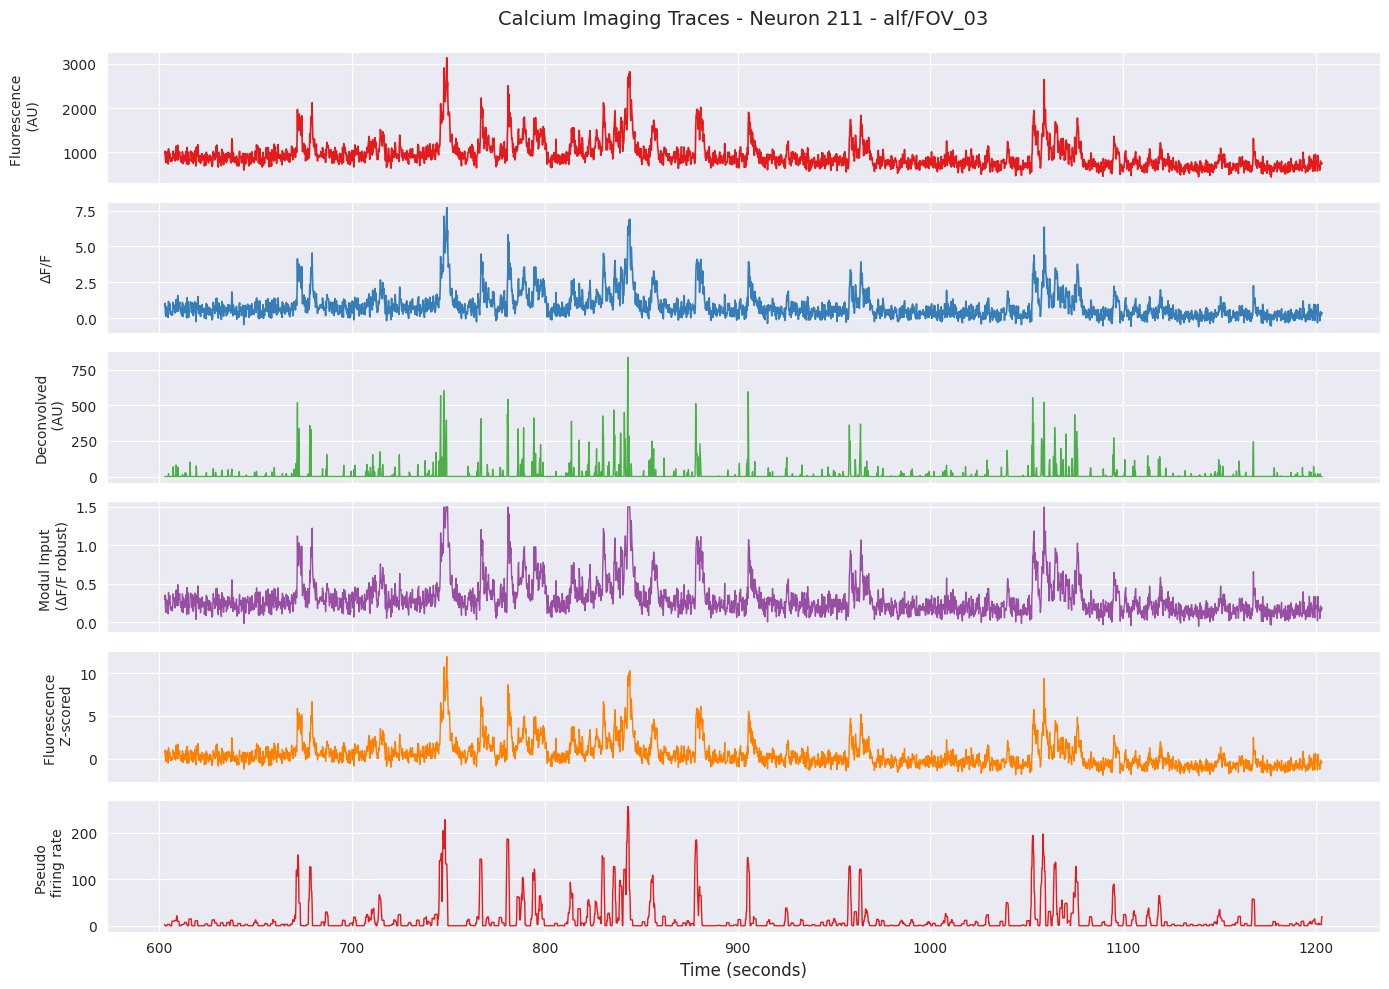

In [27]:

# Select a representative neuron and time window for visualization
neuron_idx = 211  # Same neuron used in previous plots
time_start = 3000
time_end = 6000  # Show 2000 time points for better detail

# Extract time series for selected neuron and window
time_points = timestamps[time_start:time_end]
fluor_trace = fluor[time_start:time_end, neuron_idx]
dff_trace = activity[time_start:time_end, neuron_idx]
deconv_trace = dec[time_start:time_end, neuron_idx]
robust_trace = activity_robust[time_start:time_end, neuron_idx]
pseudo_trace = pseudo[time_start:time_end, neuron_idx]
z_trace = z_score[time_start:time_end, neuron_idx]

# Create stacked plot
fig, axes = plt.subplots(6, 1, figsize=(14, 10), sharex=True)

# Set seaborn style
sns.set_style("darkgrid")
palette = sns.color_palette("Set1", 6)

# Plot 1: Raw Fluorescence
axes[0].plot(time_points, fluor_trace, color=palette[0], linewidth=1.2)
axes[0].set_ylabel('Fluorescence \n (AU)\n', fontsize=10)
axes[0].set_title(f'Calcium Imaging Traces - Neuron {neuron_idx} - {FOV_select}', fontsize=14, pad=20)
# axes[0].grid(False, alpha=0.3)

# Plot 2: ΔF/F
axes[1].plot(time_points, dff_trace, color=palette[1], linewidth=1.2)
axes[1].set_ylabel('ΔF/F\n', fontsize=10)
# axes[1].grid(False, alpha=0.3)

# Plot 3: Deconvolved
axes[2].plot(time_points, deconv_trace, color=palette[2], linewidth=1.)
axes[2].set_ylabel('Deconvolved\n (AU)', fontsize=10)

# Plot 4: Model Input
axes[3].plot(time_points, robust_trace, color=palette[3], linewidth=1.)
axes[3].set_ylabel('Modul Input \n (ΔF/F robust)', fontsize=10)

# Plot 4: Model Input
axes[4].plot(time_points, z_trace, color=palette[4], linewidth=1.)
axes[4].set_ylabel('Fluorescence \n Z-scored', fontsize=10)
# axes[2].grid(False, alpha=0.3)


# Plot 4: Rolling Average
axes[5].plot(time_points, pseudo_trace, color=palette[0], linewidth=1.)
axes[5].set_ylabel('Pseudo \n  firing rate', fontsize=10)
axes[5].set_xlabel('Time (seconds)', fontsize=12)
# axes[2].grid(False, alpha=0.3)

# Improve layout
plt.tight_layout()

# stats_text = f"""
# Data Statistics:
# • Raw Fluor mean: {fluor_trace.mean():.1f} ± {fluor_trace.std():.1f}
# • ΔF/F mean: {dff_trace.mean():.2f} ± {dff_trace.std():.2f}  
# • Deconv mean: {deconv_trace.mean():.2f} ± {deconv_trace.std():.2f}
# • Model input mean: {robust_trace.mean():.2f} ± {robust_trace.std():.2f}
# """

# fig.text(0.8, -0.10, stats_text, fontsize=10, verticalalignment='bottom',
#          bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.8))

plt.show()

In [4]:
pseudo.shape

(21157, 1461)

<Axes: >

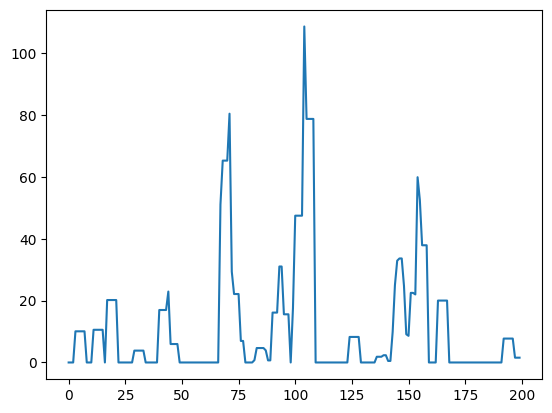

In [6]:
sns.lineplot(pseudo[500:700,50])

In [6]:
print(activity.mean(), activity.min(), activity.max(), activity.std())

activity.mean()

1.6014704 -18.755722 293.99188 2.3924305


np.float32(1.6014704)

In [7]:
robusted = robust_normalize(activity)

print(robusted.mean(), robusted.min(), robusted.max(), robusted.std())


0.33821344 -0.25 1.5 0.18740623


In [8]:
from scipy.stats import zscore

activity_zscore = zscore(activity)
activity_zscore.max()

print(activity_zscore.mean(), activity_zscore.min(), activity_zscore.max(), activity_zscore.std())


4.4230697e-10 -5.579527 47.509098 1.0000002


In [9]:
model = Rastermap(n_clusters=100, # number of clusters to compute
                  n_PCs=200, # number of PCs
                  locality=0.3, # locality in sorting is low here to get more global sorting (this is a value from 0-1)
                  time_lag_window=5, # use future timepoints to compute correlation
                  grid_upsample=10, # default value, 10 is good for large recordings
                  ).fit(activity[:, :].T)
y = model.embedding
isort = model.isort
X_embedding_activity = model.X_embedding
print(f"min {X_embedding_activity.min()} max {X_embedding_activity.max()}")

model = Rastermap(n_clusters=100, # number of clusters to compute
                  n_PCs=200, # number of PCs
                  locality=0.5, # locality in sorting is low here to get more global sorting (this is a value from 0-1)
                  time_lag_window=20, # use future timepoints to compute correlation
                  grid_upsample=10, # default value, 10 is good for large recordings
                  ).fit(activity_robust[:, :].T)
y = model.embedding
isort = model.isort
X_embedding_robust = model.X_embedding
print(f"min {X_embedding_robust.min()} max {X_embedding_robust.max()}")

2025-09-05 16:42:09,290 [INFO] normalizing data across axis=1
2025-09-05 16:42:09,363 [INFO] projecting out mean along axis=0
2025-09-05 16:42:09,479 [INFO] data normalized, 0.19sec
2025-09-05 16:42:09,479 [INFO] sorting activity: 1461 valid samples by 21157 timepoints
2025-09-05 16:42:23,954 [INFO] n_PCs = 200 computed, 14.66sec
2025-09-05 16:42:28,185 [INFO] 52 clusters computed, time 18.90sec
2025-09-05 16:42:30,416 [INFO] clusters sorted, time 21.13sec
2025-09-05 16:42:30,465 [INFO] clusters upsampled, time 21.18sec
2025-09-05 16:42:30,596 [INFO] rastermap complete, time 21.31sec
min -4.803887844085693 max 32.47005081176758
2025-09-05 16:42:30,601 [INFO] normalizing data across axis=1
2025-09-05 16:42:30,671 [INFO] projecting out mean along axis=0
2025-09-05 16:42:30,784 [INFO] data normalized, 0.18sec
2025-09-05 16:42:30,784 [INFO] sorting activity: 1461 valid samples by 21157 timepoints
2025-09-05 16:42:49,660 [INFO] n_PCs = 200 computed, 19.06sec
2025-09-05 16:42:57,481 [INFO] 5

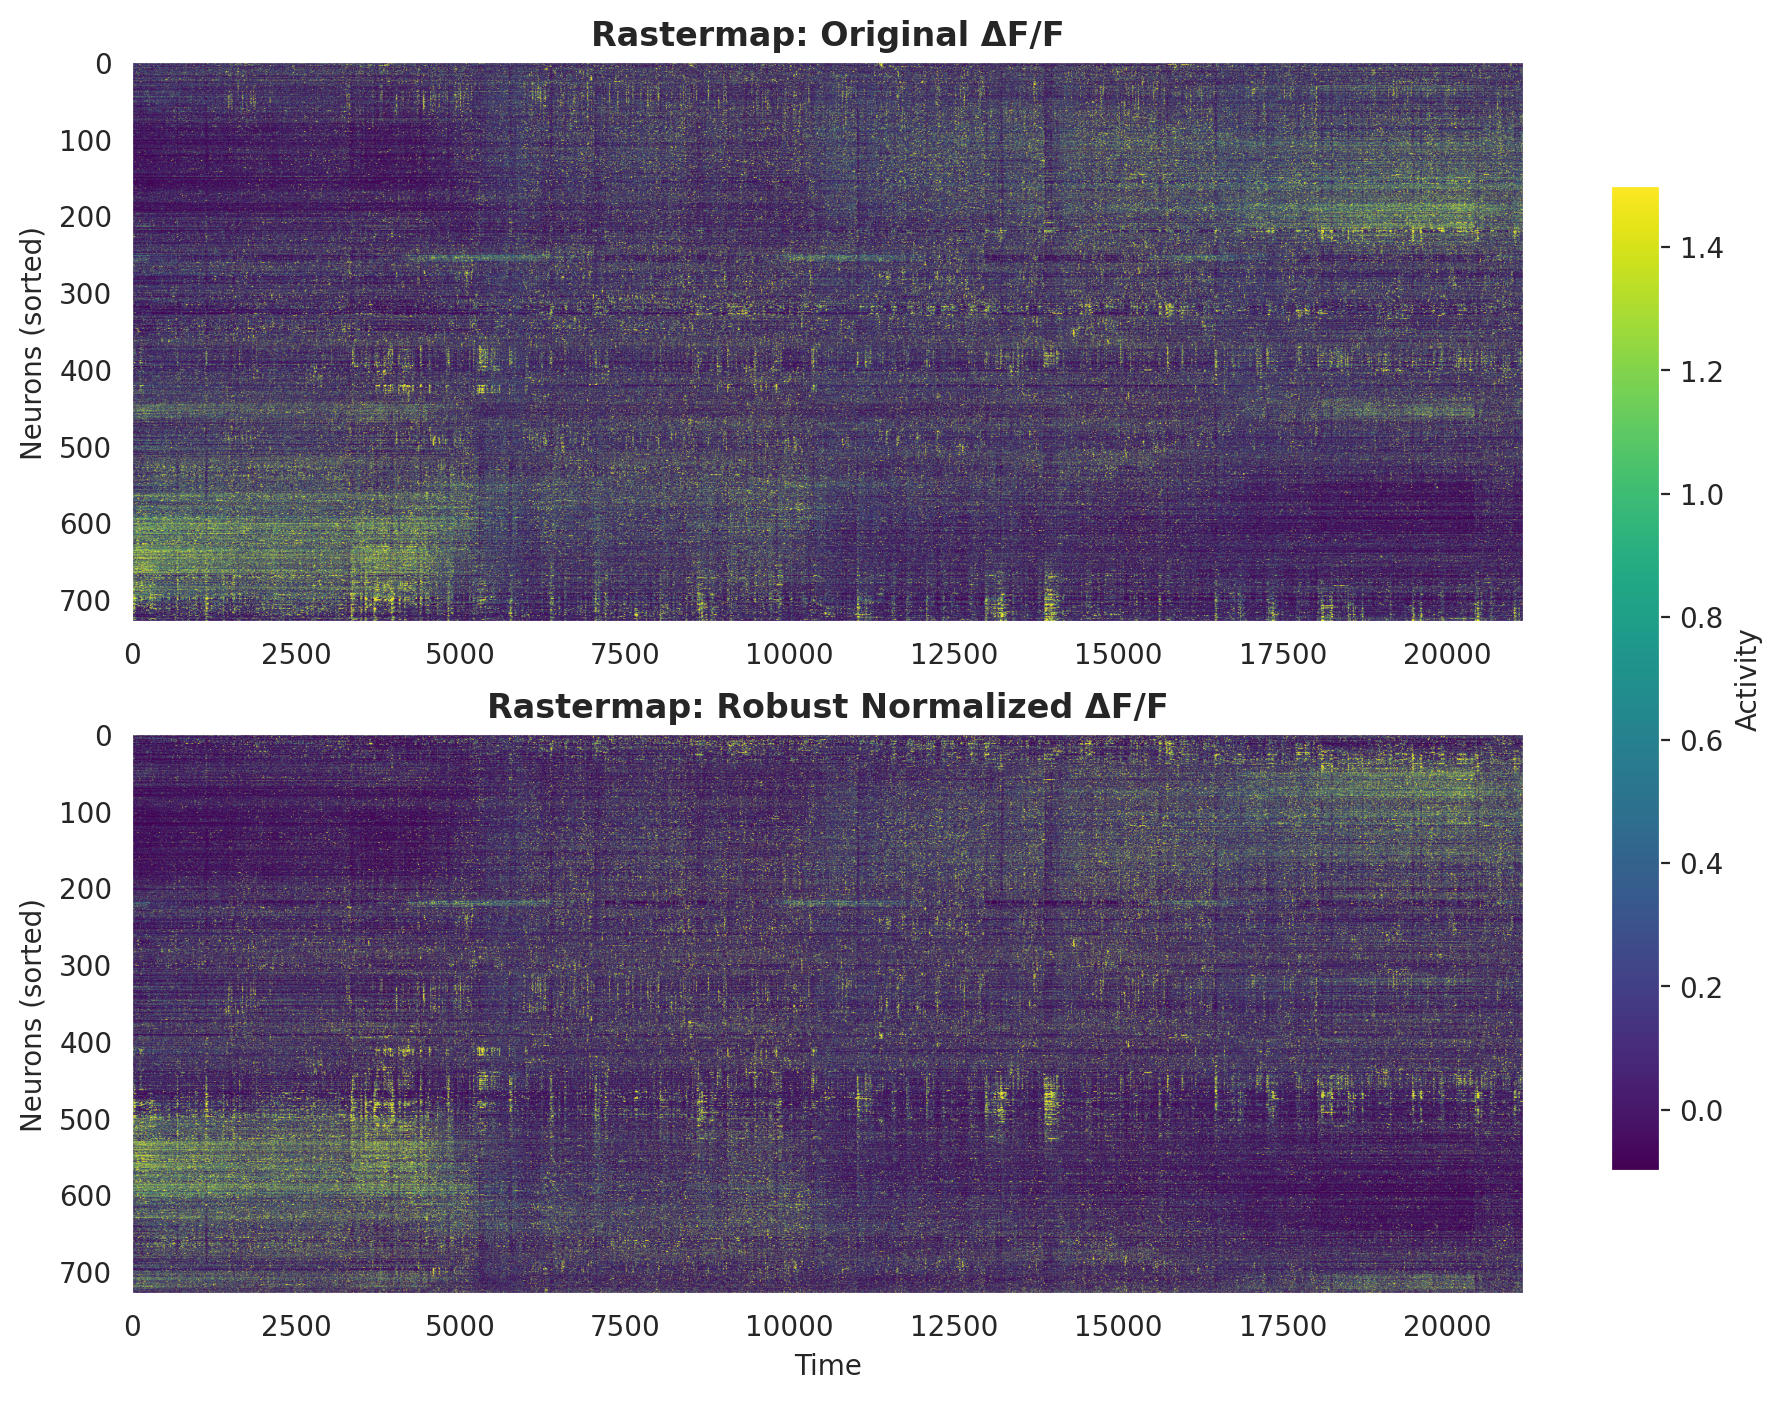

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), dpi=200)

# Plot original ΔF/F rastermap
im1 = axes[0].imshow(X_embedding_activity, vmin=-.2, vmax=1.5, cmap="viridis", aspect="auto")
axes[0].set_title('Rastermap: Original ΔF/F', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Neurons (sorted)', fontsize=10)
axes[0].grid(False)

# Plot robust normalized rastermap
im2 = axes[1].imshow(X_embedding_robust, vmin=-.1, vmax=1.5, cmap="viridis", aspect="auto")
axes[1].set_title('Rastermap: Robust Normalized ΔF/F', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Time', fontsize=10)
axes[1].set_ylabel('Neurons (sorted)', fontsize=10)
axes[1].grid(False)

# Adjust layout before adding colorbar
plt.subplots_adjust(right=0.85)

# Add colorbar
cbar = plt.colorbar(im2, ax=axes, shrink=0.8, label='Activity')

plt.show()